In [1]:
import pandas as pd 
import sys 
import numpy as np 
sys.path.append('/home/grace.bcolverd/2024-ESL-BiomassSAR')
from src.fdlbiomass.dataloader_fns import generate_quadrants, generate_dataloaders, load_biomass_data, merge_headings
from src.fdlbiomass.simple_conv import SimpleConv3D
from src.fdlbiomass.quadrant_dataset_pband import QuadrantPatchDataset 


In [2]:
train_quadrants=[2,1]
test_quadrant = 0
val_quadrant=3

parent_path = '/home/grace.bcolverd/esl_dev/tomosar-matlab/'
polarimetric_channel=['HV', 'VV', 'HH']
polarimetric_channel='HH'
band='L_Bi'
# band='P'
quadrants, ground_truths, num_channels, (crop_int, cropped_LidarCHM) = generate_quadrants(parent_path, polarimetric_channels=polarimetric_channel , band_opt=band )

Starting to load the biomass data
Load complete
merged power cube shape  (326, 840, 36, 3)
Original shape: (326, 840)
Cropped shape: (321, 665)
665 665


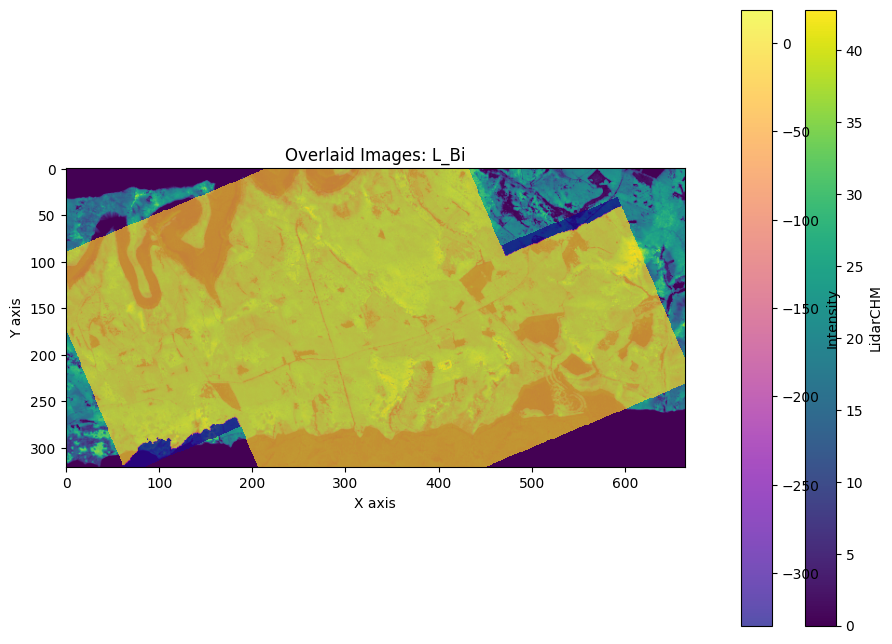

In [7]:
import matplotlib.pyplot as plt

# Create a figure and axis
f, ax = plt.subplots(figsize=(10, 8))

# Plot the first image
im1 = ax.imshow(cropped_LidarCHM, cmap='viridis')

# Plot the second image with transparency
im2 = ax.imshow(crop_int[:,:,35,0], cmap='plasma', alpha=0.7)


# Add colorbars for both images
plt.colorbar(im1, ax=ax, label='LidarCHM', orientation='vertical', fraction=0.046, pad=0.04)
plt.colorbar(im2, ax=ax, label='Intensity', orientation='vertical', fraction=0.046, pad=0.08)

# Set title and labels
ax.set_title(f'Overlaid Images: {band}')
ax.set_xlabel('X axis')
ax.set_ylabel('Y axis')

# Show the plot
plt.show()

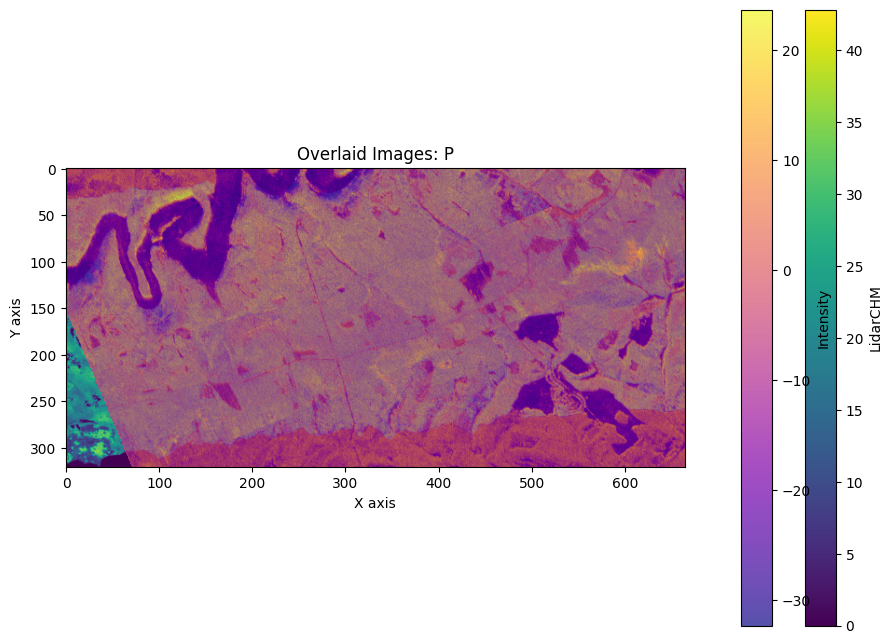

In [38]:
import matplotlib.pyplot as plt

# Create a figure and axis
f, ax = plt.subplots(figsize=(10, 8))

# Plot the first image
im1 = ax.imshow(cropped_LidarCHM, cmap='viridis')

# Plot the second image with transparency
im2 = ax.imshow(crop_int[:,:,0,0], cmap='plasma', alpha=0.7)


# Add colorbars for both images
plt.colorbar(im1, ax=ax, label='LidarCHM', orientation='vertical', fraction=0.046, pad=0.04)
plt.colorbar(im2, ax=ax, label='Intensity', orientation='vertical', fraction=0.046, pad=0.08)

# Set title and labels
ax.set_title(f'Overlaid Images: {band}')
ax.set_xlabel('X axis')
ax.set_ylabel('Y axis')

# Show the plot
plt.show()

In [27]:
band_opt='L_Bi'

data = load_biomass_data(parent_path, band_opt)
    
head=0
if band_opt =='L_Mono':
    pcube = data['PcubeDeRampedDeBiasedUTM']
    mono_bi_ind = 0 
 
elif band_opt =='L_Bi':
    pcube = data['PcubeDeRampedDeBiasedUTM']
    mono_bi_ind = 1 
    
 




Starting to load the biomass data


Load complete


In [28]:
pcube.shape

(326, 840, 36, 3, 2, 2)

In [21]:
nw = pcube[:,:,:, 0]
se = pcube[:,:,:,1]

In [24]:
nw.shape, se.shape

((326, 840, 36), (326, 840, 36))

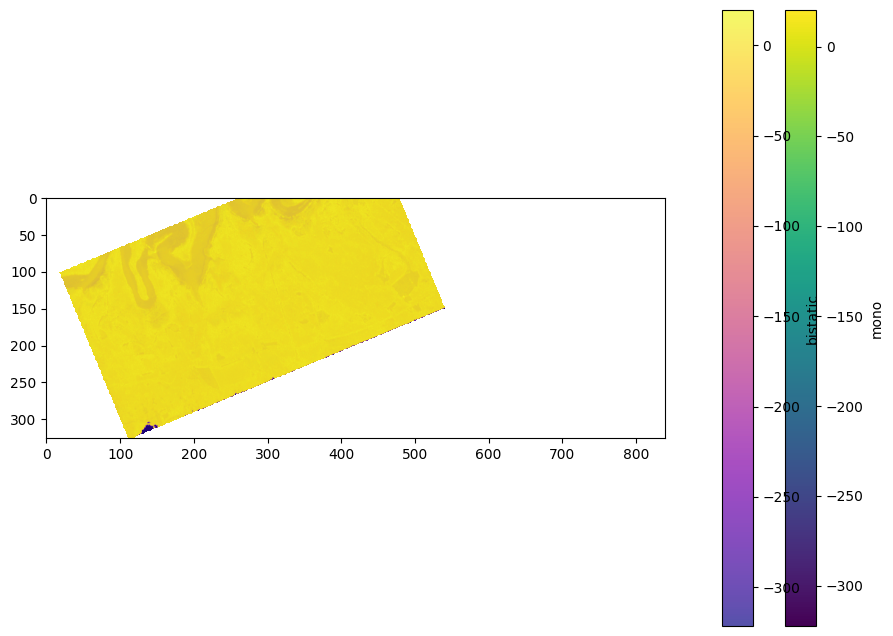

In [34]:
import matplotlib.pyplot as plt

# Create a figure and axis
f, ax = plt.subplots(figsize=(10, 8))
z=10 
pol = 0 
heading = 0


# Plot the first image
im1 = ax.imshow(pcube[:,:,z, pol, 0,  heading]  , cmap='viridis')

# Plot the second image with transparency
im2 = ax.imshow(pcube[:,:,z, pol, 1, heading ] , cmap='plasma', alpha=0.7)
# im3 = ax.imshow(crop_int[:,:,0,0,1], cmap='plasma', alpha=0.7)

# Add colorbars for both images
plt.colorbar(im1, ax=ax, label='mono', orientation='vertical', fraction=0.046, pad=0.04)
plt.colorbar(im2, ax=ax, label='bistatic', orientation='vertical', fraction=0.046, pad=0.08)


# Show the plot
plt.show()

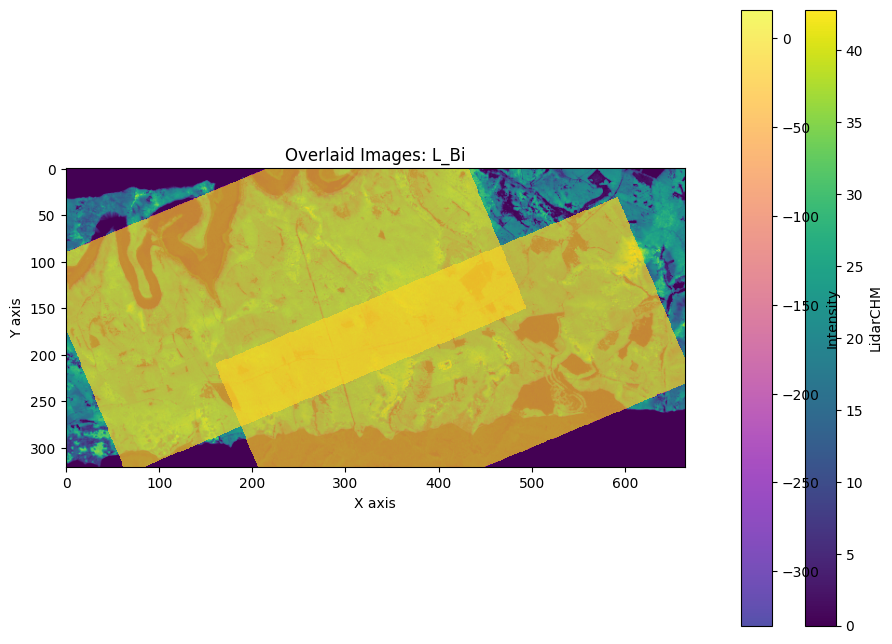

In [5]:
import matplotlib.pyplot as plt

# Create a figure and axis
f, ax = plt.subplots(figsize=(10, 8))

# Plot the first image
im1 = ax.imshow(cropped_LidarCHM, cmap='viridis')

# Plot the second image with transparency
im2 = ax.imshow(crop_int[:,:,0,0,0], cmap='plasma', alpha=0.7)
im3 = ax.imshow(crop_int[:,:,0,0,1], cmap='plasma', alpha=0.7)

# Add colorbars for both images
plt.colorbar(im1, ax=ax, label='LidarCHM', orientation='vertical', fraction=0.046, pad=0.04)
plt.colorbar(im2, ax=ax, label='Intensity', orientation='vertical', fraction=0.046, pad=0.08)

# Set title and labels
ax.set_title(f'Overlaid Images: {band}')
ax.set_xlabel('X axis')
ax.set_ylabel('Y axis')

# Show the plot
plt.show()

In [1]:
# check that filter of 35% nulls working 

import matplotlib.pyplot as plt
import numpy as np

# Assuming you have already created your dataset
dataset = QuadrantPatchDataset(quadrants, ground_truths, [0,1], 3, 2)

# Calculate zero percentages and counts
zero_percentages, all_zero_count, non_zero_count = dataset.calculate_zero_percentages()

# Create a figure with two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Histogram of zero percentages
ax1.hist(zero_percentages, bins=50, edgecolor='black')
ax1.set_title('Histogram of Percentage of Zero Values in Lidar Patches')
ax1.set_xlabel('Percentage of Zero Values')
ax1.set_ylabel('Count')

# Plot 2: Bar plot of all-zero vs non-all-zero patches
labels = ['All Zeros', 'Contains Non-Zeros']
counts = [all_zero_count, non_zero_count]
ax2.bar(labels, counts)
ax2.set_title('Count of All-Zero vs Non-All-Zero Patches')
ax2.set_ylabel('Count')

# Add value labels on top of each bar
for i, count in enumerate(counts):
    ax2.text(i, count, str(count), ha='center', va='bottom')

plt.tight_layout()
plt.show()

# Print some statistics
total_patches = all_zero_count + non_zero_count
print(f"Total patches: {total_patches}")
print(f"All-zero patches: {all_zero_count} ({all_zero_count/total_patches*100:.2f}%)")
print(f"Patches with non-zero values: {non_zero_count} ({non_zero_count/total_patches*100:.2f}%)")
print(f"Patches with more than 50% zeros: {sum(p > 50 for p in zero_percentages)}")
print(f"Patches with more than 90% zeros: {sum(p > 90 for p in zero_percentages)}")

NameError: name 'QuadrantPatchDataset' is not defined

In [14]:
train_loader, test_loader, val_loader, train_dataset, (input_scaler, gt_scaler), val_quadrant = generate_dataloaders(quadrants, ground_truths, (16,16,36), (8,8,36), test_quadrant=3, batch_size=4)

Quadrant shape: torch.Size([160, 332, 36, 1]) -> torch.Size([160, 336, 36, 1])
Ground truth shape: torch.Size([160, 332]) -> torch.Size([160, 336])
Quadrant shape: torch.Size([160, 333, 36, 1]) -> torch.Size([160, 336, 36, 1])
Ground truth shape: torch.Size([160, 333]) -> torch.Size([160, 336])
Quadrant shape: torch.Size([161, 332, 36, 1]) -> torch.Size([168, 336, 36, 1])
Ground truth shape: torch.Size([161, 332]) -> torch.Size([168, 336])
Quadrant shape: torch.Size([161, 333, 36, 1]) -> torch.Size([168, 336, 36, 1])
Ground truth shape: torch.Size([161, 333]) -> torch.Size([168, 336])


Total valid patches: 1979
Quadrant 0: 466 valid patches
Quadrant 1: 490 valid patches
Quadrant 2: 580 valid patches
Quadrant 3: 443 valid patches
Dataset Initialization Information:
Patch size: (16, 16, 36)
Stride: (8, 8, 36)

Quadrant 0:
  Original shape: torch.Size([160, 332, 36, 1])
  Padded shape: torch.Size([160, 336, 36, 1])
  Ground truth shape: torch.Size([160, 332])
  Padded ground truth shape: torch.Size([160, 336])

Quadrant 1:
  Original shape: torch.Size([160, 333, 36, 1])
  Padded shape: torch.Size([160, 336, 36, 1])
  Ground truth shape: torch.Size([160, 333])
  Padded ground truth shape: torch.Size([160, 336])

Quadrant 2:
  Original shape: torch.Size([161, 332, 36, 1])
  Padded shape: torch.Size([168, 336, 36, 1])
  Ground truth shape: torch.Size([161, 332])
  Padded ground truth shape: torch.Size([168, 336])

Quadrant 3:
  Original shape: torch.Size([161, 333, 36, 1])
  Padded shape: torch.Size([168, 336, 36, 1])
  Ground truth shape: torch.Size([161, 333])
  Padded g

239 111 145


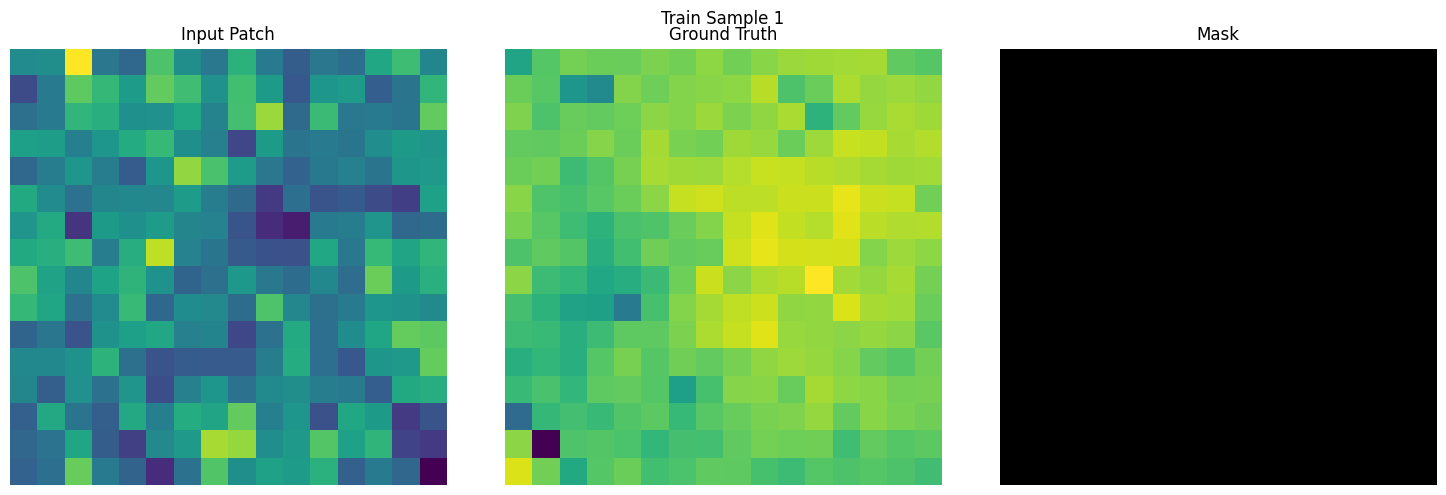

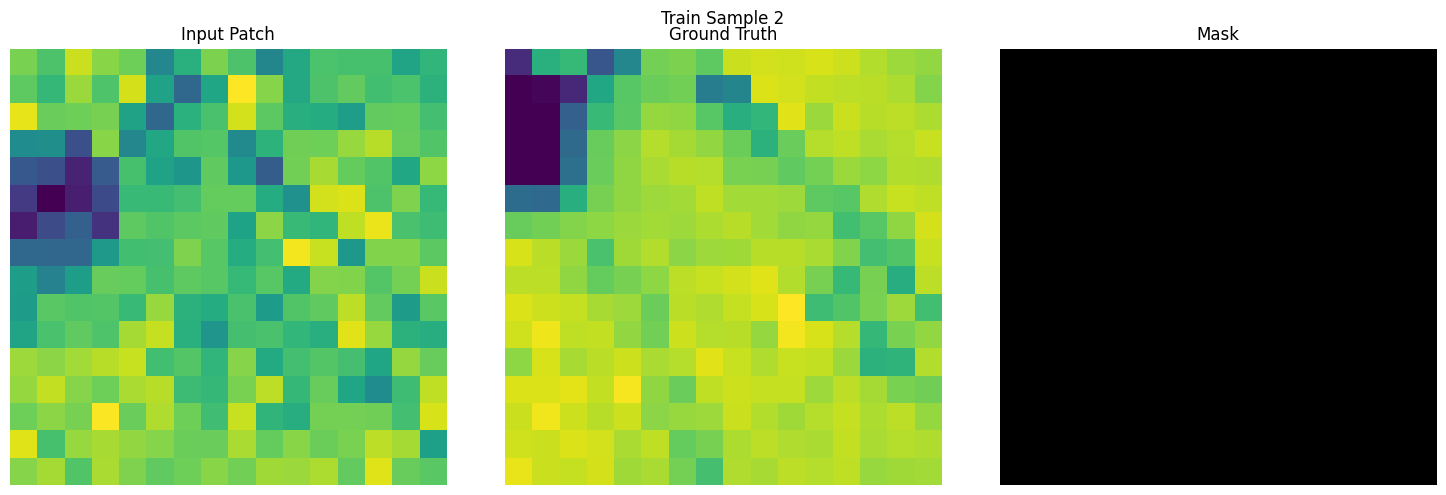

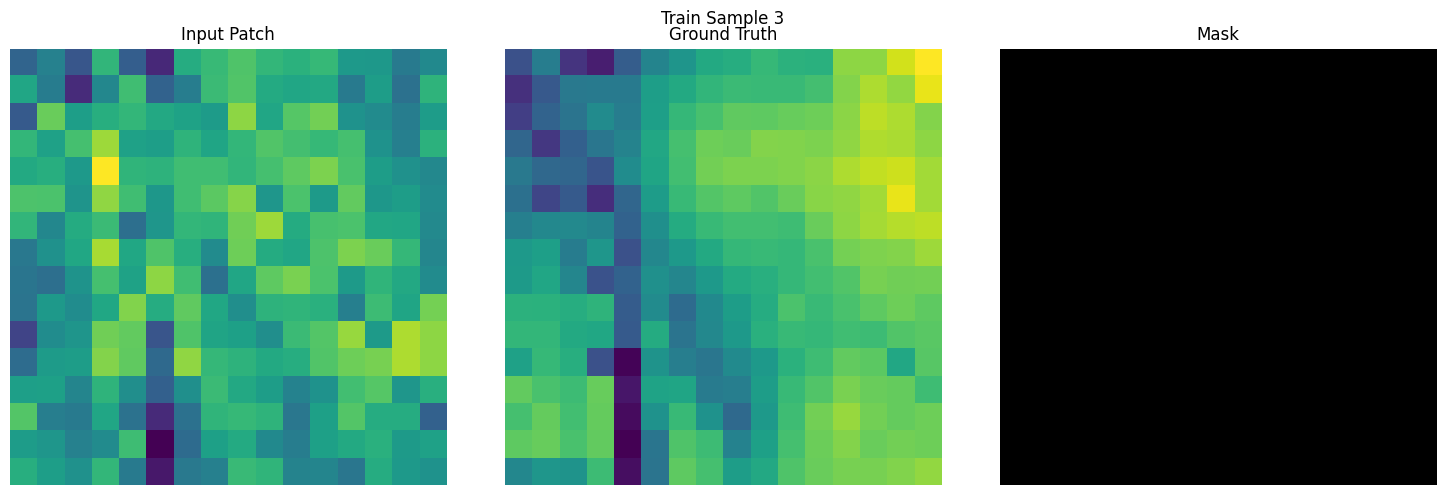

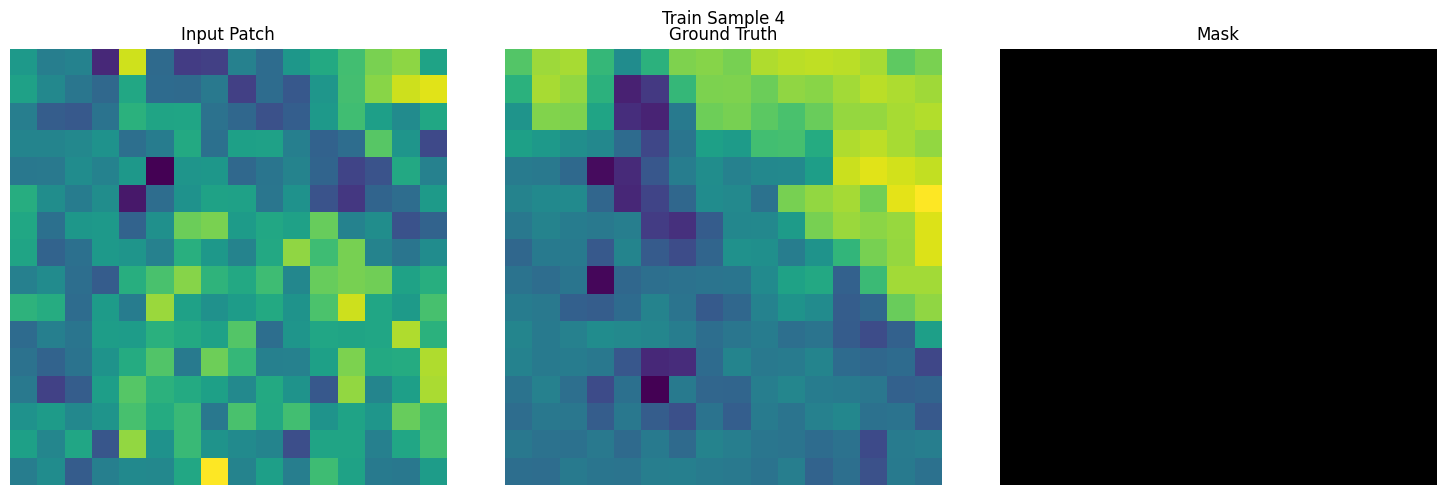

In [15]:
import matplotlib.pyplot as plt
import torch

def plot_loader_samples(loader, num_samples=5, title_prefix=""):
    # Get a batch of data
    batch = next(iter(loader))
    input_patches, ground_truths, masks = batch

    # Plot num_samples from the batch
    for i in range(min(num_samples, len(input_patches))):
        fig, axs = plt.subplots(1, 3, figsize=(15, 5))
        fig.suptitle(f"{title_prefix} Sample {i+1}")

        # Plot input patch (first channel, first time step)
        axs[0].imshow(input_patches[i, 0, :, :, 0].cpu().numpy(), cmap='viridis')
        axs[0].set_title("Input Patch")
        axs[0].axis('off')

        # Plot ground truth
        axs[1].imshow(ground_truths[i].cpu().numpy(), cmap='viridis')
        axs[1].set_title("Ground Truth")
        axs[1].axis('off')

        # Plot mask
        axs[2].imshow(masks[i].cpu().numpy(), cmap='gray')
        axs[2].set_title("Mask")
        axs[2].axis('off')

        plt.tight_layout()
        plt.show()

print(len(train_loader), len(test_loader), len(val_loader))
# Usage:
plot_loader_samples(train_loader, title_prefix="Train")


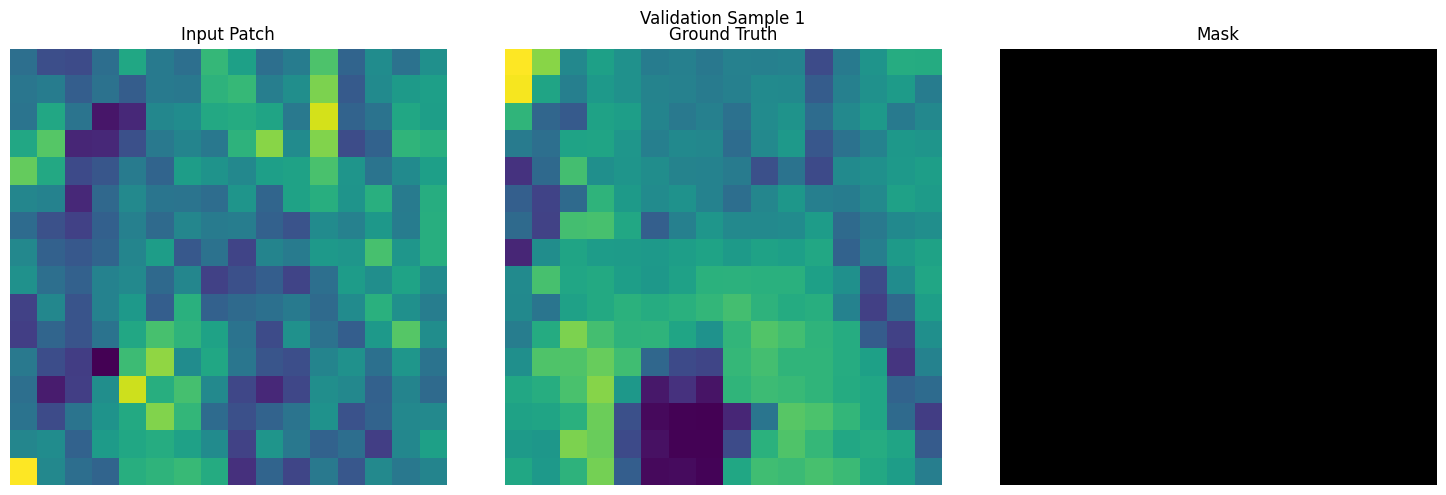

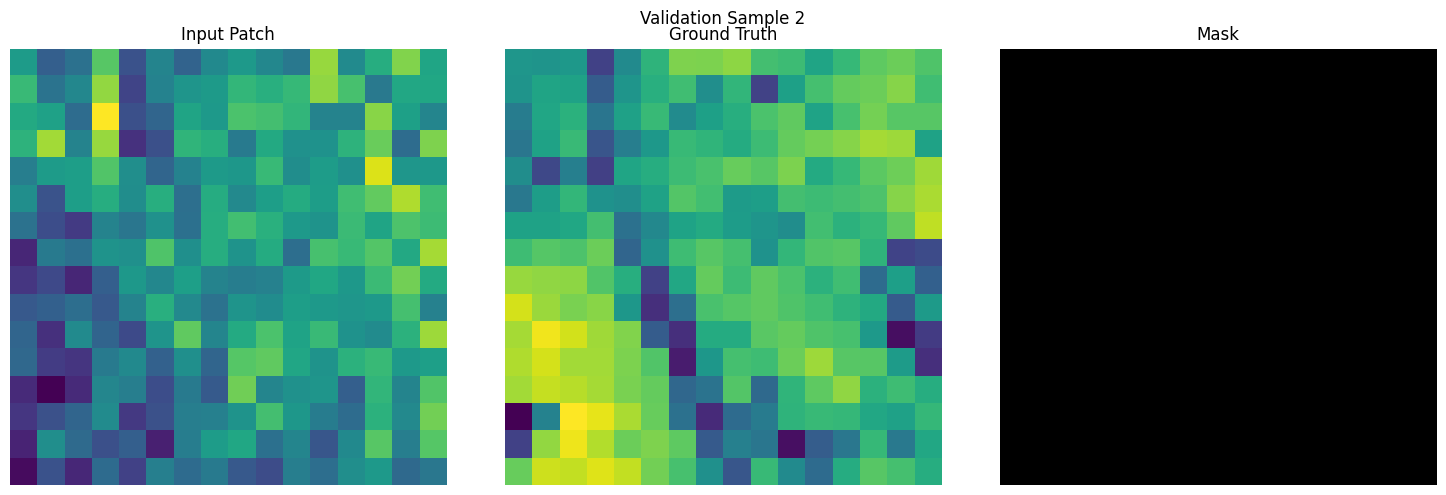

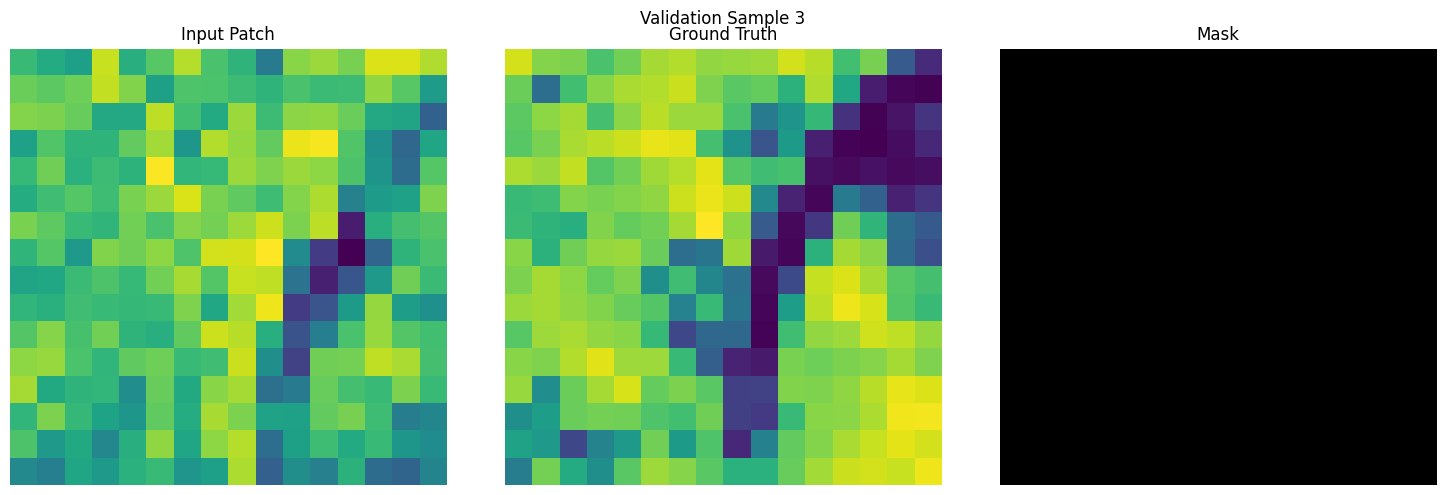

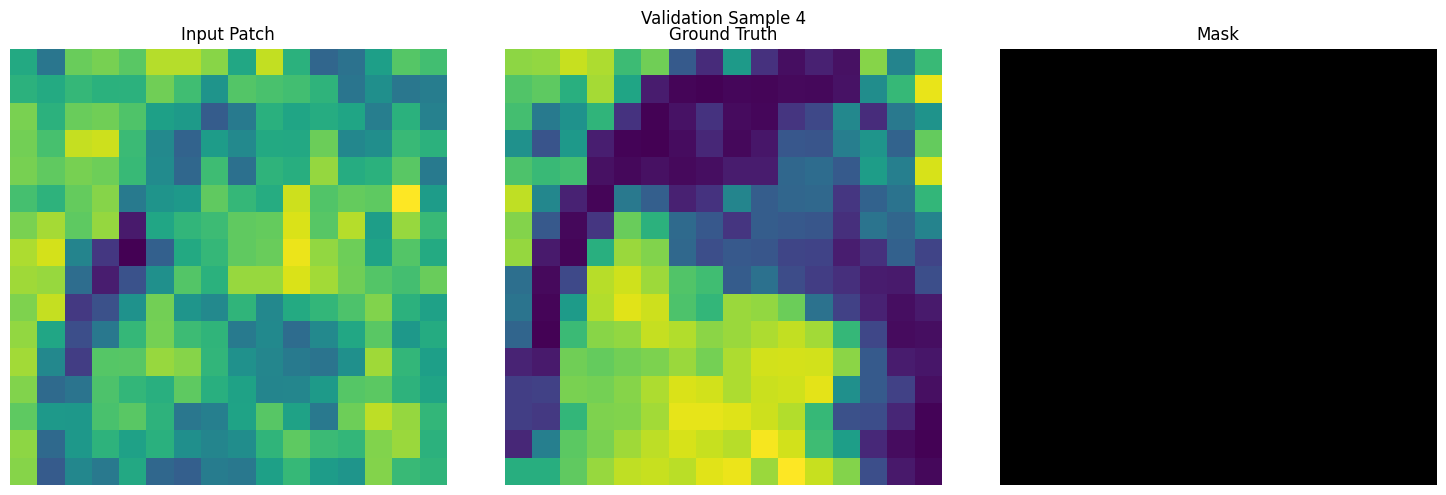

In [16]:
plot_loader_samples(val_loader, title_prefix="Validation")

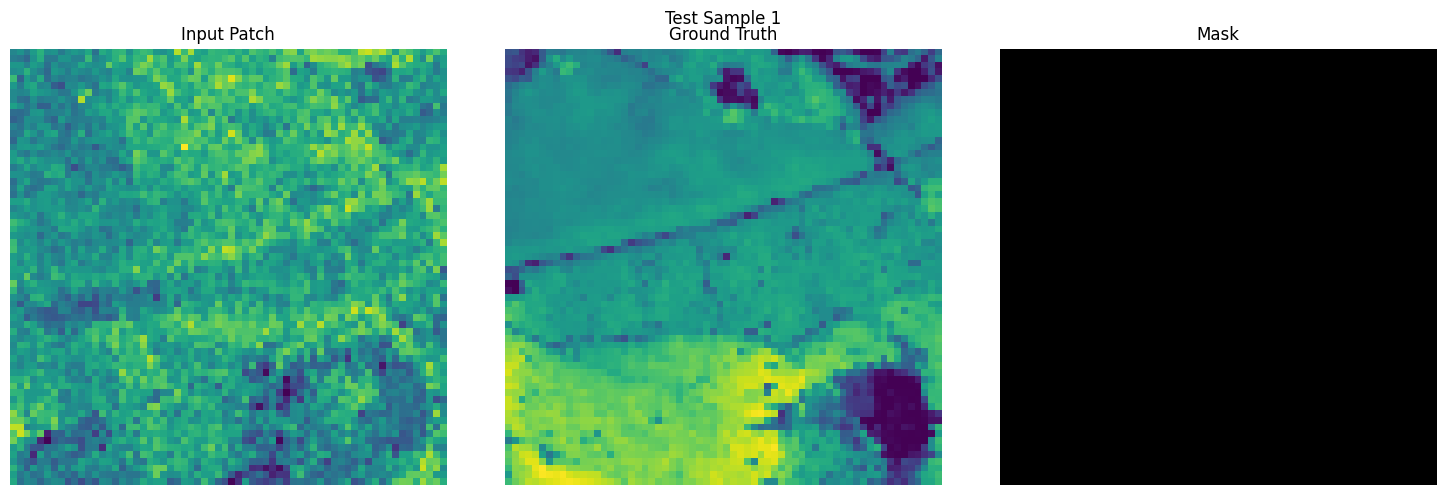

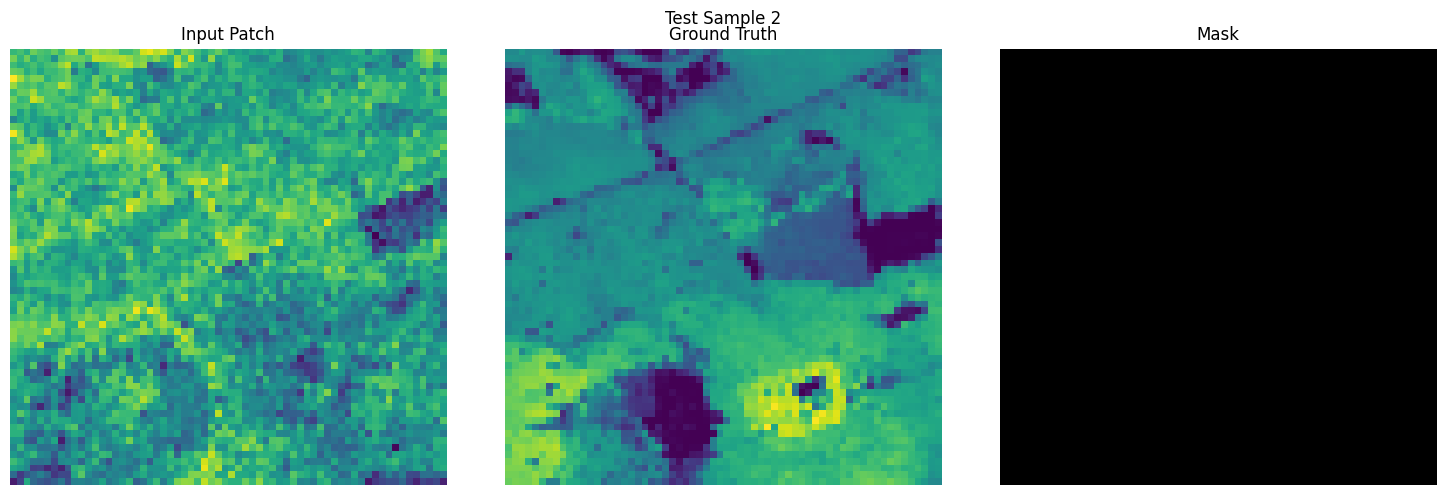

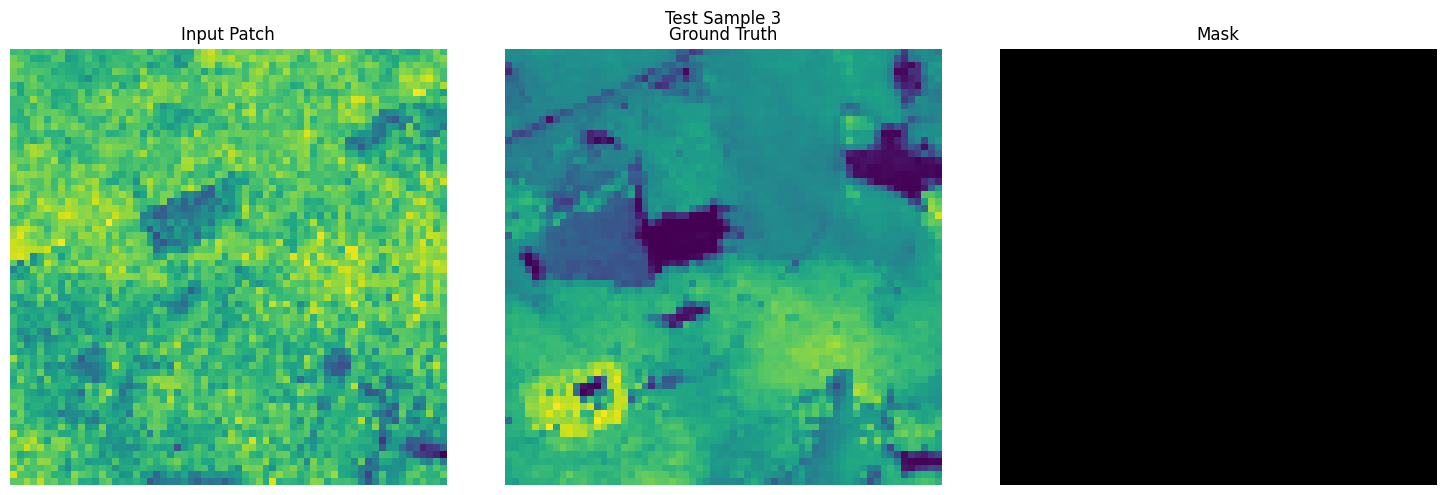

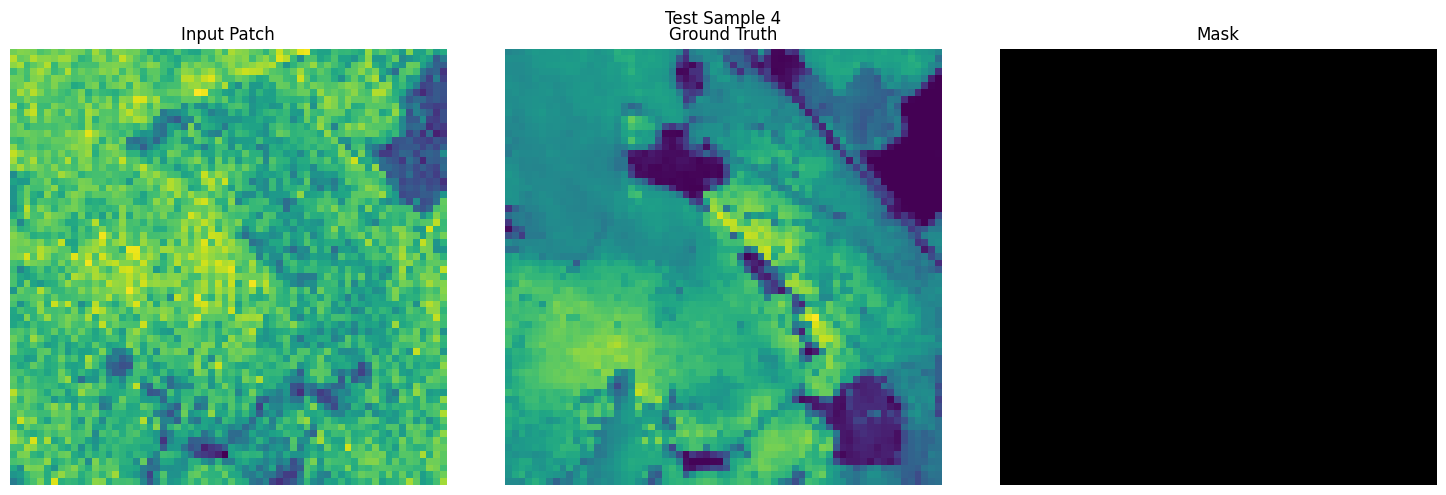

In [12]:
plot_loader_samples(test_loader, title_prefix="Test")


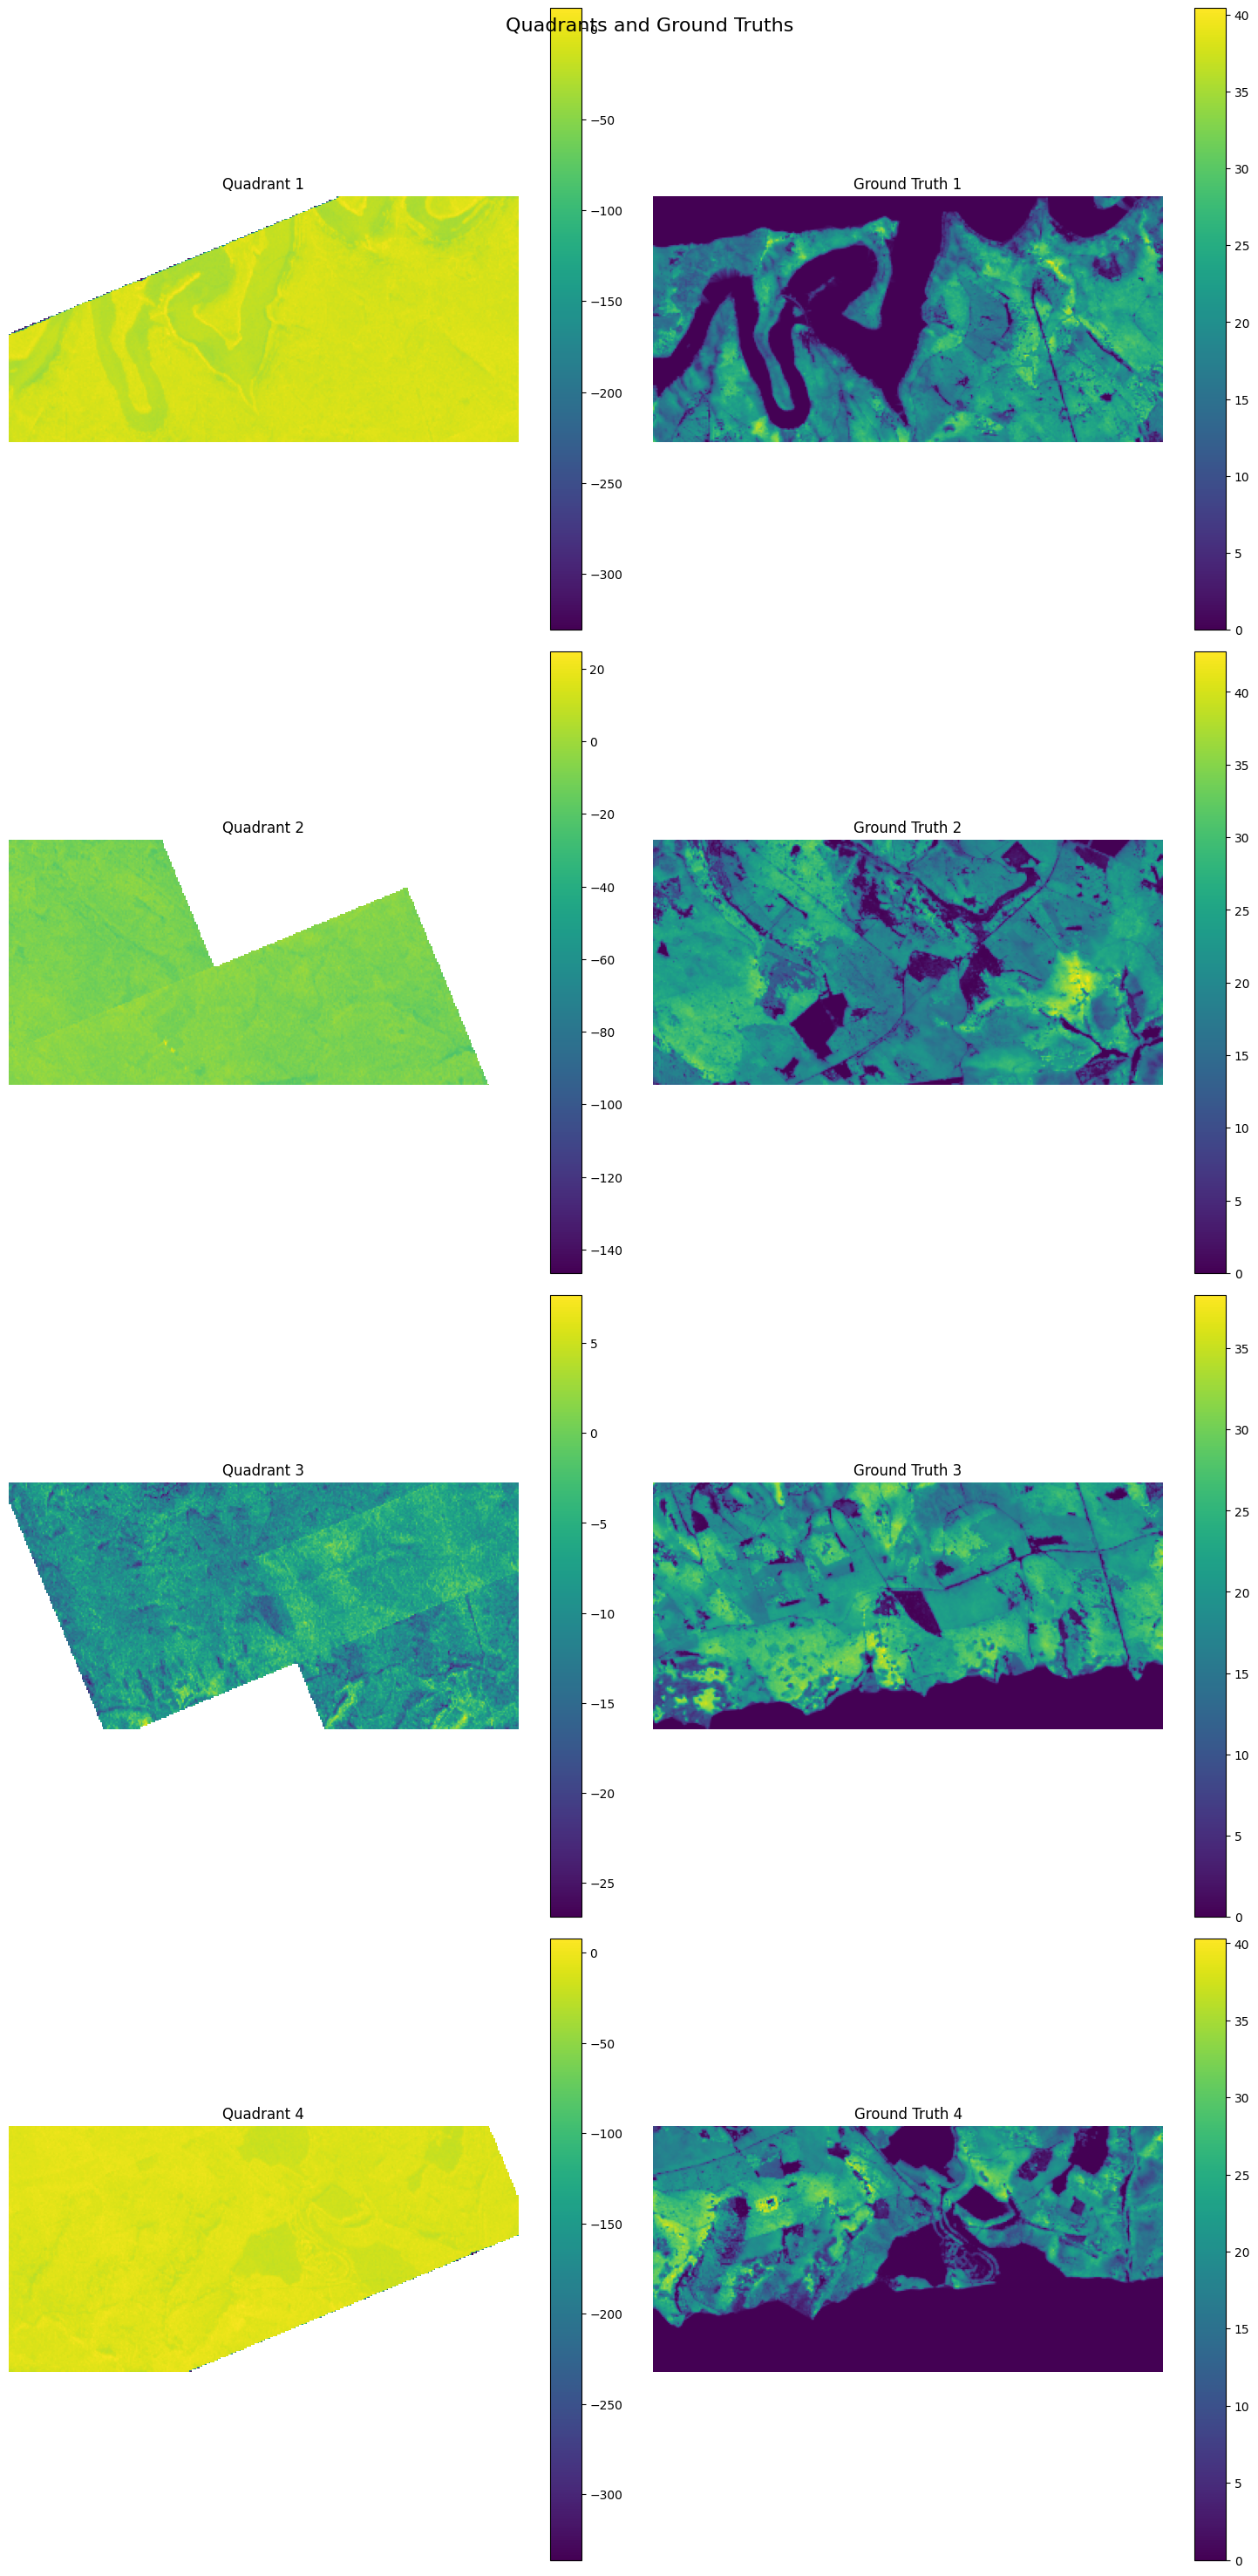

In [17]:
import matplotlib.pyplot as plt
import numpy as np

def plot_quadrants_and_ground_truths(quadrants, ground_truths):
    assert len(quadrants) == len(ground_truths) == 4, "Expected 4 quadrants and 4 ground truths"

    fig, axs = plt.subplots(4, 2, figsize=(15, 30))
    fig.suptitle("Quadrants and Ground Truths", fontsize=16)

    for i in range(4):
        quadrant = quadrants[i]
        ground_truth = ground_truths[i]

        # Plot quadrant
        if quadrant.ndim == 4:  # If multi-channel
            # Use the first channel and first time step for visualization
            quadrant_plot = quadrant[:, :, 0, 0]
        elif quadrant.ndim == 3:  # If single-channel
            quadrant_plot = quadrant[:, :, 0]
        else:
            quadrant_plot = quadrant

        im1 = axs[i, 0].imshow(quadrant_plot, cmap='viridis')
        axs[i, 0].set_title(f"Quadrant {i+1}")
        fig.colorbar(im1, ax=axs[i, 0])

        # Plot ground truth
        im2 = axs[i, 1].imshow(ground_truth, cmap='viridis')
        axs[i, 1].set_title(f"Ground Truth {i+1}")
        fig.colorbar(im2, ax=axs[i, 1])

        # Turn off axis labels
        axs[i, 0].axis('off')
        axs[i, 1].axis('off')

    plt.tight_layout()
    plt.show()

# Usage:
# quadrants, ground_truths, num_channels, _ = generate_quadrants(parent_path, polarimetric_channels, band_opt)
plot_quadrants_and_ground_truths(quadrants, ground_truths)

Quadrant shape: torch.Size([160, 332, 36, 1]) -> torch.Size([160, 336, 36, 1])
Ground truth shape: torch.Size([160, 332]) -> torch.Size([160, 336])
Quadrant shape: torch.Size([160, 333, 36, 1]) -> torch.Size([160, 336, 36, 1])
Ground truth shape: torch.Size([160, 333]) -> torch.Size([160, 336])
Quadrant shape: torch.Size([161, 332, 36, 1]) -> torch.Size([176, 336, 36, 1])
Ground truth shape: torch.Size([161, 332]) -> torch.Size([176, 336])
Quadrant shape: torch.Size([161, 333, 36, 1]) -> torch.Size([176, 336, 36, 1])
Ground truth shape: torch.Size([161, 333]) -> torch.Size([176, 336])
Total valid patches: 274
Quadrant 0: 65 valid patches
Quadrant 1: 58 valid patches
Quadrant 2: 84 valid patches
Quadrant 3: 67 valid patches
Dataset Initialization Information:
Patch size: (64, 64, 36)
Stride: (16, 16, 36)

Quadrant 0:
  Original shape: torch.Size([160, 332, 36, 1])
  Padded shape: torch.Size([160, 336, 36, 1])
  Ground truth shape: torch.Size([160, 332])
  Padded ground truth shape: torc

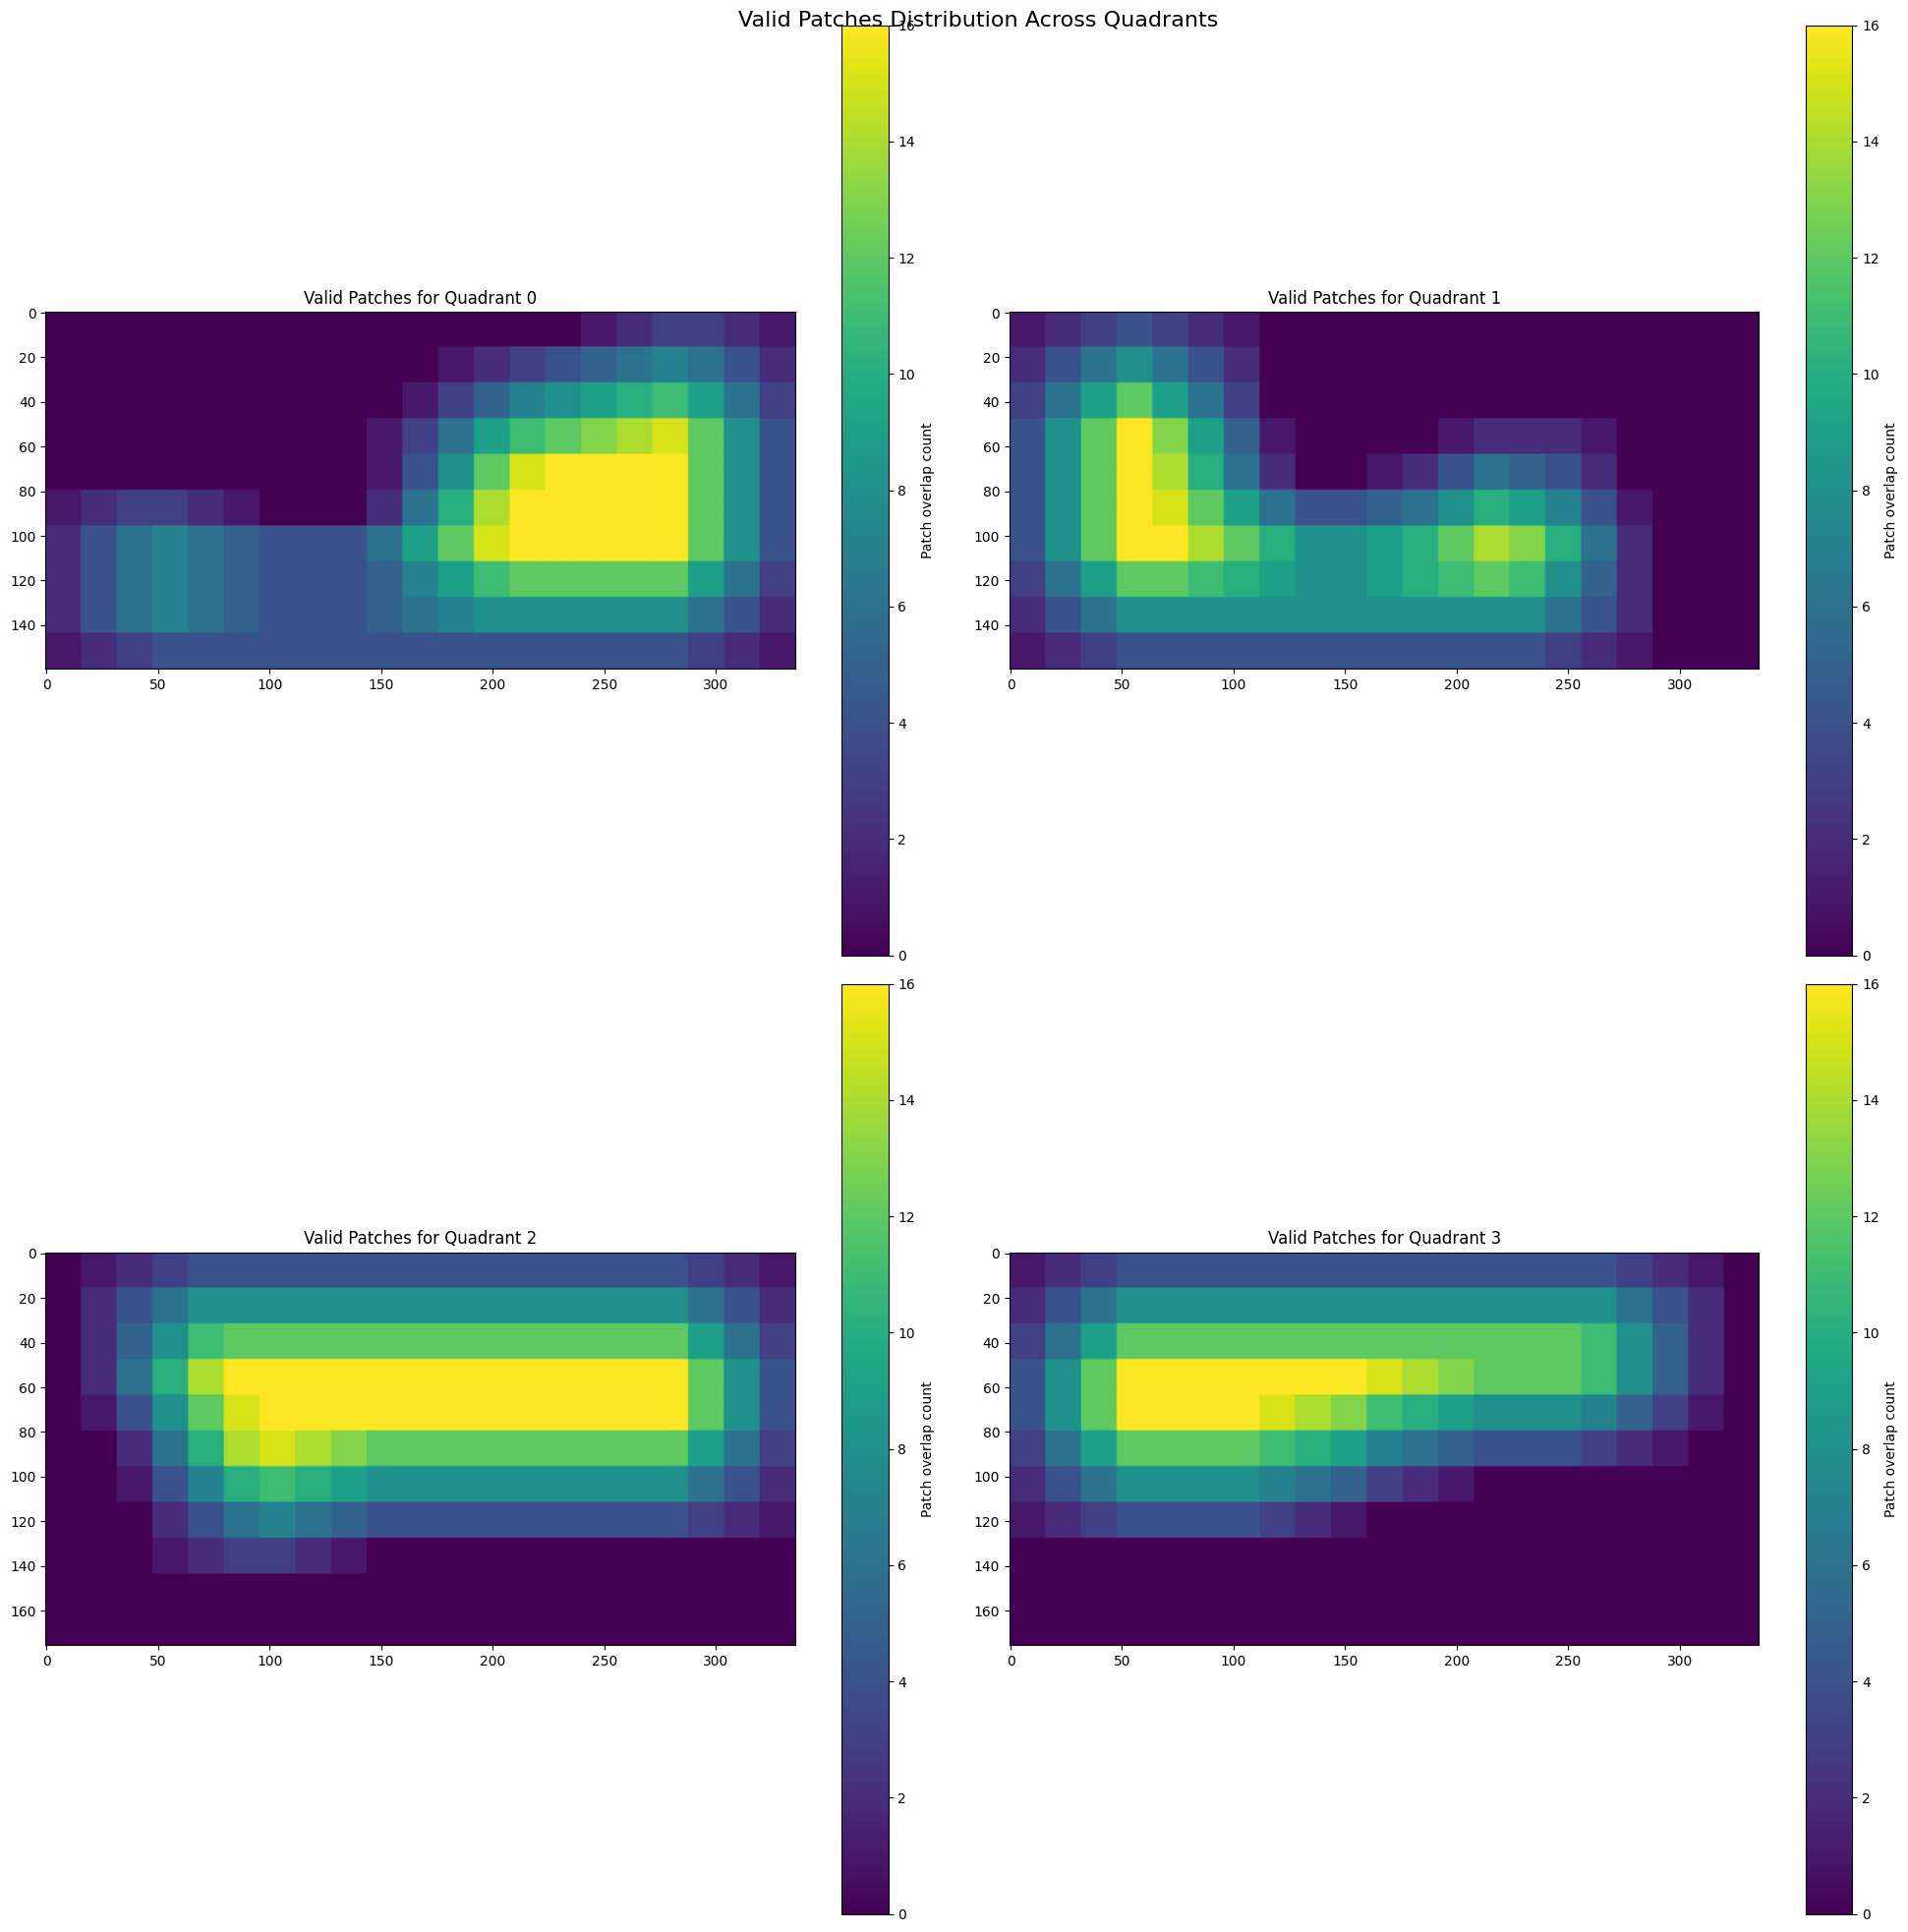

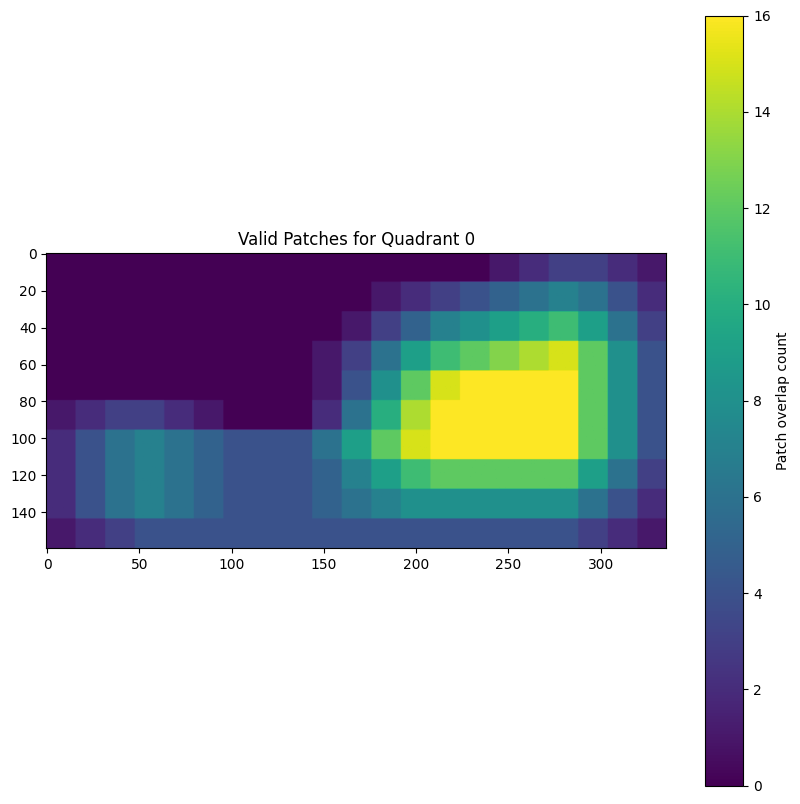

In [18]:
import matplotlib.pyplot as plt

def visualize_all_quadrants(dataset):
    num_quadrants = len(dataset.quadrants)
    fig, axs = plt.subplots(2, 2, figsize=(20, 20))
    fig.suptitle("Valid Patches Distribution Across Quadrants", fontsize=16)

    for quadrant_idx in range(num_quadrants):
        row = quadrant_idx // 2
        col = quadrant_idx % 2
        
        # Get the patch map for this quadrant
        quadrant = dataset.padded_quadrants[quadrant_idx]
        h, w = quadrant.shape[:2]
        patch_map = torch.zeros((h, w), dtype=torch.int)
        
        for patch_idx in dataset.valid_indices[quadrant_idx]:
            cols = (w - dataset.patch_size[1]) // dataset.stride[1] + 1
            row_start = (patch_idx // cols) * dataset.stride[0]
            col_start = (patch_idx % cols) * dataset.stride[1]
            patch_map[row_start:row_start+dataset.patch_size[0], 
                      col_start:col_start+dataset.patch_size[1]] += 1
        
        # Plot the patch map
        im = axs[row, col].imshow(patch_map.cpu().numpy(), cmap='viridis')
        axs[row, col].set_title(f'Valid Patches for Quadrant {quadrant_idx}')
        fig.colorbar(im, ax=axs[row, col], label='Patch overlap count')

    plt.tight_layout()
    plt.show()

# Usage:
# Assuming you've already created your dataset
dataset = QuadrantPatchDataset(quadrants, ground_truths, train_quadrants, test_quadrant, val_quadrant)

# Visualize patches for all quadrants
visualize_all_quadrants(dataset)

# If you want to visualize a specific quadrant:
quadrant_to_visualize = 0  # Change this to visualize different quadrants
dataset.visualize_patches(quadrant_to_visualize)

In [14]:
import torch
import matplotlib.pyplot as plt

def check_min_max_scaling(train_loader):
    # Get a batch of data
    batch = next(iter(train_loader))
    
    # Print the batch structure
    print("Batch type:", type(batch))
    print("Batch length:", len(batch))
    
    # Collect all inputs and targets from the batch
    all_inputs = []
    all_targets = []
    for item in batch:
        inputs, targets = item
        all_inputs.append(inputs)
        all_targets.append(targets)
    
    inputs = torch.stack(all_inputs)
    targets = torch.stack(all_targets)
    
    print("Inputs shape:", inputs.shape)
    print("Targets shape:", targets.shape)

    # Check the range of the input data
    input_min = torch.min(inputs)
    input_max = torch.max(inputs)
    input_mean = torch.mean(inputs)
    
    print(f"Input Min value: {input_min.item():.4f}")
    print(f"Input Max value: {input_max.item():.4f}")
    print(f"Input Mean value: {input_mean.item():.4f}")

    # Check the range of the target data
    target_min = torch.min(targets)
    target_max = torch.max(targets)
    target_mean = torch.mean(targets)
    
    print(f"Target Min value: {target_min.item():.4f}")
    print(f"Target Max value: {target_max.item():.4f}")
    print(f"Target Mean value: {target_mean.item():.4f}")

    # Plot histogram of the input data
    plt.figure(figsize=(10, 5))
    plt.hist(inputs.cpu().numpy().flatten(), bins=50)
    plt.title("Distribution of Input Values After Min-Max Scaling")
    plt.xlabel("Value")
    plt.ylabel("Frequency")
    plt.show()

    # Plot histogram of the target data
    plt.figure(figsize=(10, 5))
    plt.hist(targets.cpu().numpy().flatten(), bins=50)
    plt.title("Distribution of Target Values After Min-Max Scaling")
    plt.xlabel("Value")
    plt.ylabel("Frequency")
    plt.show()

    # Visualize a sample input
    sample_input = inputs[0, 0]  # First item in batch, first channel

    plt.figure(figsize=(15, 5))
    plt.subplot(1, 3, 1)
    plt.imshow(sample_input[:,:,0].cpu(), cmap='viridis')
    plt.title(f"Sample Input (Channel 0)\nMin: {sample_input.min().item():.4f}, Max: {sample_input.max().item():.4f}")
    plt.colorbar()

    plt.subplot(1, 3, 2)
    plt.imshow(sample_input[:,:,sample_input.shape[2]//2].cpu(), cmap='viridis')
    plt.title(f"Sample Input (Middle Channel)")
    plt.colorbar()

    plt.subplot(1, 3, 3)
    plt.imshow(sample_input[:,:,-1].cpu(), cmap='viridis')
    plt.title(f"Sample Input (Last Channel)")
    plt.colorbar()

    plt.tight_layout()
    plt.show()

    # Visualize a sample target
    sample_target = targets[0]  # First item in batch

    plt.figure(figsize=(10, 5))
    plt.imshow(sample_target.cpu(), cmap='viridis')
    plt.title(f"Sample Target\nMin: {sample_target.min().item():.4f}, Max: {sample_target.max().item():.4f}")
    plt.colorbar()
    plt.show()

# Use the function
check_min_max_scaling(train_loader)

NameError: name 'train_loader' is not defined